[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch12_sam.ipynb)

# 12장 SAM · 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

1. SAM 불러오기와 구조 보기 (12.3절)
2. 실습 ①: 점·박스 프롬프트로 분할하기 (12.4절)
3. 자동으로 전체 분할하기 (12.4절)
4. 실습 ②: 7장 용종 사진에 SAM 적용하기 — U-Net과 비교 (12.7절)
5. 실습 ③: YOLO로 찾고 SAM으로 칠하기 (12.8절)

**런타임 → 런타임 유형 변경 → T4 GPU**로 바꾼 뒤 실행하세요. GPU에서 모두 실행하면 25분쯤 걸립니다.
> 이 장도 11장처럼 Hugging Face의 `transformers` 라이브러리로 사전학습 모델을 내려받아 씁니다. 학습은 하지 않고 추론만 합니다.

예시 사진: SAM 공식 저장소(facebookresearch/segment-anything, Apache 2.0)의 예제 사진

## 0. 준비

In [1]:
!pip -q install ultralytics          # 7장에서 쓴 YOLO 라이브러리
import os, glob, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import transformers
from transformers import SamModel, SamProcessor, Sam2Model, Sam2Processor, pipeline
from scipy.ndimage import distance_transform_edt
from ultralytics import YOLO

device = 'cuda' if torch.cuda.is_available() else 'cpu'
transformers.set_seed(42)
print(torch.__version__, transformers.__version__, device, torch.cuda.get_device_name() if device == 'cuda' else '')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
2.11.0+cu130 5.21.0 cuda Tesla T4


In [2]:
base = 'https://raw.githubusercontent.com/facebookresearch/segment-anything/main/notebooks/images'
for f in ['truck.jpg', 'groceries.jpg', 'dog.jpg']:
    os.system(f'wget -q {base}/{f} -O {f}')
print(sorted(glob.glob('*.jpg')))

['dog.jpg', 'groceries.jpg', 'truck.jpg']


마스크를 사진 위에 겹쳐 그리는 함수를 만들어 둡니다.

In [3]:
def show_mask(mask, ax, color=(0.12, 0.56, 1.0), alpha=0.5):
    h, w = mask.shape
    ax.imshow(np.dstack([np.ones((h, w, 3)) * color, mask * alpha]))

def show_points(points, labels, ax):
    for (x, y), l in zip(points, labels):
        ax.plot(x, y, marker='*', markersize=18, color='lime' if l == 1 else 'red',
                markeredgecolor='white')

def show_box(box, ax, color='lime'):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, lw=2))

## 1. SAM 불러오기와 구조 보기
SAM은 세 부분으로 되어 있습니다.
- **이미지 인코더**: 사진을 16×16 조각으로 나눠 트랜스포머(ViT)로 읽고, 64×64 크기의 특성 맵(이미지 임베딩)으로 바꿉니다.
- **프롬프트 인코더**: 점·박스를 벡터로 바꿉니다.
- **마스크 디코더**: 이미지 임베딩과 프롬프트 벡터로 마스크를 그립니다.

가장 작은 SAM(ViT-B)을 불러와 부분마다 파라미터 수를 세어 봅니다.

In [4]:
sam = SamModel.from_pretrained('facebook/sam-vit-base').to(device).eval()
proc = SamProcessor.from_pretrained('facebook/sam-vit-base')
count = lambda m: sum(p.numel() for p in m.parameters())
print(f'이미지 인코더:     {count(sam.vision_encoder):>12,}')
print(f'프롬프트 인코더:   {count(sam.prompt_encoder):>12,}')
print(f'마스크 디코더:     {count(sam.mask_decoder):>12,}')
print(f'전체:              {count(sam):>12,}')

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

이미지 인코더:       89,670,912
프롬프트 인코더:          6,476
마스크 디코더:        4,058,340
전체:                93,735,728


사진은 긴 변을 1024픽셀로 맞춰 넣습니다. 이미지 인코더를 거치면 256채널의 64×64 특성 맵이 됩니다.
이미지 인코더는 무겁지만 **사진마다 한 번만** 돌리면 되고, 프롬프트를 바꿀 때마다 돌리는 디코더는 아주 가볍습니다. 시간을 재 봅니다.

In [5]:
truck = Image.open('truck.jpg').convert('RGB')
print('사진 크기:', truck.size)
inputs = proc(images=truck, return_tensors='pt').to(device)
print('입력 크기:', tuple(inputs['pixel_values'].shape))

with torch.no_grad():
    sam.get_image_embeddings(inputs['pixel_values'])          # 처음 한 번은 준비 시간이 섞이므로 버린다
    if device == 'cuda': torch.cuda.synchronize()
    t = time.time()
    emb = sam.get_image_embeddings(inputs['pixel_values'])    # 이미지 인코더만
    if device == 'cuda': torch.cuda.synchronize()
    t_enc = time.time() - t
print('이미지 임베딩:', tuple(emb.shape), f'/ 인코더 {t_enc * 1000:.0f}ms')

def segment(image, emb, points=None, labels=None, box=None, multimask=True):
    """이미 계산한 이미지 임베딩에 프롬프트만 넣어 마스크를 얻는다"""
    kw = {}
    if points is not None: kw.update(input_points=[[points]], input_labels=[[labels]])
    if box is not None: kw.update(input_boxes=[[box]])
    inp = proc(images=image, return_tensors='pt', **kw).to(device)
    inp.pop('pixel_values')
    with torch.no_grad():
        out = sam(image_embeddings=emb, multimask_output=multimask, **inp)
    masks = proc.post_process_masks(out.pred_masks.cpu(), inp['original_sizes'].cpu(),
                                    inp['reshaped_input_sizes'].cpu())[0][0].numpy()
    return masks, out.iou_scores[0, 0].cpu().numpy()

p = proc(images=truck, input_points=[[[[500, 375]]]], input_labels=[[[1]]], return_tensors='pt').to(device)
with torch.no_grad():
    if device == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for _ in range(10):      # 프롬프트 인코더 + 마스크 디코더만
        sam(image_embeddings=emb, input_points=p['input_points'], input_labels=p['input_labels'])
    if device == 'cuda': torch.cuda.synchronize()
print(f'프롬프트 인코더 + 마스크 디코더(프롬프트 한 번): {(time.time() - t) / 10 * 1000:.0f}ms')

사진 크기: (1800, 1200)
입력 크기: (1, 3, 1024, 1024)
이미지 임베딩: (1, 256, 64, 64) / 인코더 384ms
프롬프트 인코더 + 마스크 디코더(프롬프트 한 번): 39ms


## 2. 실습 ①: 점·박스 프롬프트로 분할하기
### 점 하나
트럭의 뒤쪽 창문에 점 하나(초록 별)를 찍습니다. 점 하나로는 "창문"을 원하는지, "창문들"을 원하는지, "트럭 전체"를 원하는지 알 수 없습니다.
그래서 SAM은 마스크를 **세 개** 내고, 마스크마다 스스로 매긴 점수(예상 IoU)를 함께 냅니다.

마스크 수: 3
마스크 0: 점수 0.905, 사진에서 차지하는 비율 26.5%
마스크 1: 점수 0.951, 사진에서 차지하는 비율 2.1%
마스크 2: 점수 0.983, 사진에서 차지하는 비율 1.0%


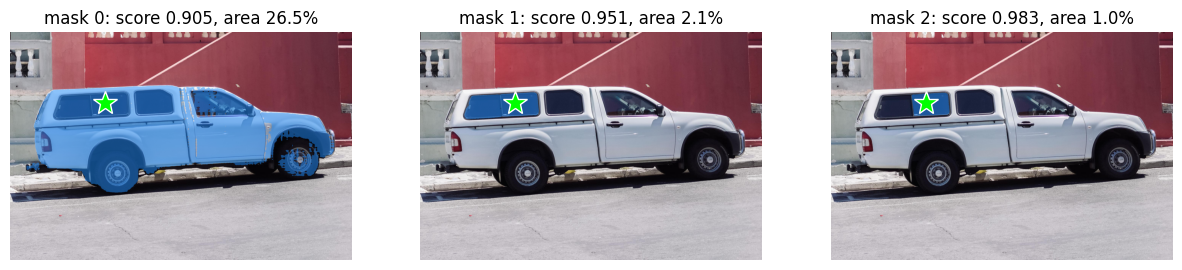

In [6]:
pt, lb = [[500, 375]], [1]
masks, scores = segment(truck, emb, points=pt, labels=lb)
print('마스크 수:', len(masks))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, ax in enumerate(axes):
    ax.imshow(truck); show_mask(masks[i], ax); show_points(pt, lb, ax); ax.axis('off')
    ax.set_title(f'mask {i}: score {scores[i]:.3f}, area {masks[i].mean() * 100:.1f}%')
    print(f'마스크 {i}: 점수 {scores[i]:.3f}, 사진에서 차지하는 비율 {masks[i].mean() * 100:.1f}%')
plt.show()

### 박스
트럭을 감싸는 박스를 주면 무엇을 원하는지 분명하므로 마스크 하나만 받습니다.

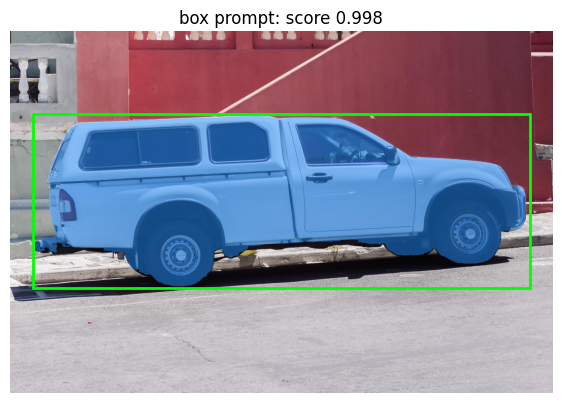

점수 0.998, 사진에서 차지하는 비율 29.0%


In [7]:
box = [75, 275, 1725, 850]
masks, scores = segment(truck, emb, box=box, multimask=False)
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(truck); show_mask(masks[0], ax); show_box(box, ax); ax.axis('off')
ax.set_title(f'box prompt: score {scores[0]:.3f}')
plt.show()
print(f'점수 {scores[0]:.3f}, 사진에서 차지하는 비율 {masks[0].mean() * 100:.1f}%')

### 점 여러 개
점을 하나 더 찍으면(앞문) 원하는 것이 "트럭" 쪽이라는 정보가 늘어납니다.

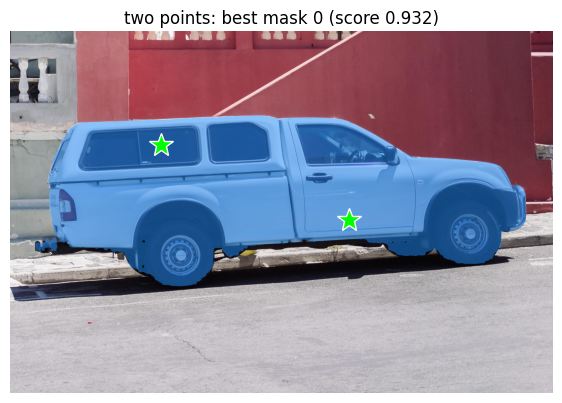

점수: [      0.932       0.852       0.889] / 가장 높은 마스크의 비율: 28.9%


In [8]:
pt2, lb2 = [[500, 375], [1125, 625]], [1, 1]
masks, scores = segment(truck, emb, points=pt2, labels=lb2)
best = scores.argmax()
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(truck); show_mask(masks[best], ax); show_points(pt2, lb2, ax); ax.axis('off')
ax.set_title(f'two points: best mask {best} (score {scores[best]:.3f})')
plt.show()
print('점수:', scores.round(3), '/ 가장 높은 마스크의 비율:', f'{masks[best].mean() * 100:.1f}%')

## 3. 자동으로 전체 분할하기
프롬프트 없이 사진 전체를 나누고 싶을 때는 사진 위에 32×32개의 점을 고르게 찍어 점마다 마스크를 얻고, 점수가 높고 서로 겹치지 않는 마스크만 남깁니다.
`transformers`의 `mask-generation` 파이프라인이 이 일을 해 줍니다.

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

찾은 마스크 수: 91 / 6.0s


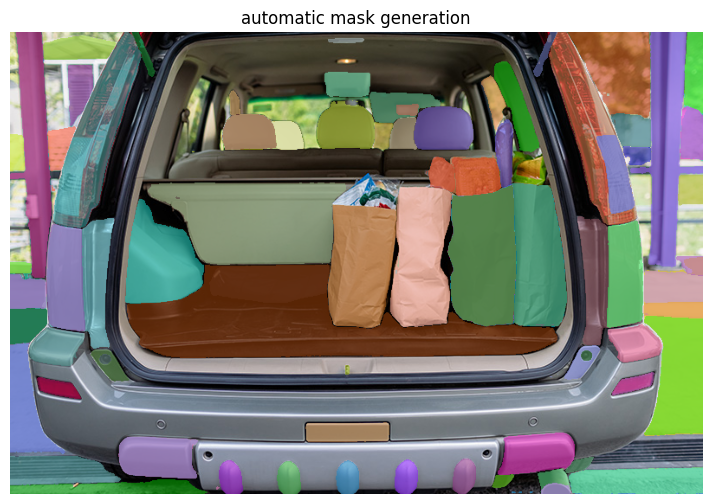

In [9]:
generator = pipeline('mask-generation', model='facebook/sam-vit-base', device=0 if device == 'cuda' else -1)
groceries = Image.open('groceries.jpg').convert('RGB')
t = time.time()
auto = generator(groceries, points_per_batch=64)
print(f'찾은 마스크 수: {len(auto["masks"])} / {time.time() - t:.1f}s')

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(groceries)
rng = np.random.default_rng(0)
masks_auto = [torch.as_tensor(m).cpu().numpy() for m in auto['masks']]
for m in sorted(masks_auto, key=lambda m: -m.sum()):    # 큰 마스크부터 칠한다
    show_mask(m, ax, color=rng.random(3), alpha=0.55)
ax.axis('off'); ax.set_title('automatic mask generation')
plt.show()

마스크마다 "무엇"인지는 나오지 않습니다. SAM은 물체의 **경계**를 찾을 뿐, 그것이 종이봉투인지 자동차인지는 모릅니다.

## 4. 실습 ②: 7장 용종 사진에 SAM 적용하기
7장에서는 Kvasir-SEG 사진 800장으로 U-Net을 학습해 테스트 100장에서 Dice 평균 0.662를 얻었습니다.
SAM은 용종 사진을 한 장도 보고 학습하지 않았습니다. 같은 테스트 100장에 SAM을 그대로 적용하면 어떨까요?

데이터는 7장과 같은 방법으로 내려받습니다.

In [10]:
# 중간 인증서를 받아 시스템 인증서 목록에 더한다(7장과 같음)
!wget -q http://crt.sectigo.com/SectigoPublicServerAuthenticationCADVR36.crt -O sectigo.der
!openssl x509 -inform DER -in sectigo.der -out sectigo.pem
!cat /etc/ssl/certs/ca-certificates.crt sectigo.pem > ca-bundle.pem
!wget -q --ca-certificate=ca-bundle.pem https://datasets.simula.no/downloads/kvasir-seg.zip
!unzip -q -o kvasir-seg.zip
image_paths = sorted(glob.glob('Kvasir-SEG/images/*.jpg'))
mask_paths = sorted(glob.glob('Kvasir-SEG/masks/*.jpg'))
test_idx = np.random.default_rng(42).permutation(len(image_paths))[900:]    # 7장과 같은 테스트 100장
print(len(image_paths), len(test_idx))

1000 100


SAM은 프롬프트가 있어야 합니다. 여기서는 사람이 프롬프트를 준다고 가정하고, 정답 마스크로 두 가지 프롬프트를 만듭니다.
- **점**: 용종 안에서 경계에서 가장 먼 점 하나 (의사가 용종 한가운데를 클릭한 셈)
- **박스**: 용종을 꼭 맞게 감싸는 박스 (의사가 용종 둘레에 박스를 그린 셈)

점 프롬프트에서는 마스크 세 개 중 SAM이 매긴 점수가 가장 높은 것을 고릅니다.
평가는 7장과 똑같이 마스크를 256×256으로 줄여 Dice를 잽니다.

In [11]:
IMG_SIZE = 256

def dice(a, b):
    total = a.sum() + b.sum()
    return 2 * np.logical_and(a, b).sum() / total if total > 0 else 1.0

def prompts_from_mask(gt):
    ys, xs = np.where(gt)
    box = [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]
    dist = distance_transform_edt(gt)                      # 경계까지의 거리
    y, x = np.unravel_index(dist.argmax(), dist.shape)     # 경계에서 가장 먼 점
    return [[int(x), int(y)]], box

def run_sam(model, processor, image, point=None, box=None):
    # 마스크 후보들과 SAM이 매긴 점수를 돌려준다(점: 3개, 박스: 1개)
    kw = dict(input_points=[[point]], input_labels=[[[1]]]) if point else dict(input_boxes=[[box]])
    inp = processor(images=image, return_tensors='pt', **kw).to(device)
    with torch.no_grad():
        out = model(**inp, multimask_output=point is not None)
    extra = {'reshaped_input_sizes': inp['reshaped_input_sizes'].cpu()} if 'reshaped_input_sizes' in inp else {}
    masks = processor.post_process_masks(out.pred_masks.cpu(), inp['original_sizes'].cpu(), **extra)[0][0].numpy()
    return masks, out.iou_scores[0, 0].cpu().numpy()

to256 = lambda m: np.array(Image.fromarray(m).resize((IMG_SIZE, IMG_SIZE), Image.NEAREST))

def evaluate(model, processor):
    res = {'point': [], 'point_best3': [], 'box': []}
    for i in test_idx:
        image = Image.open(image_paths[i]).convert('RGB')
        gt_img = Image.open(mask_paths[i]).convert('L')
        gt = np.array(gt_img) > 127
        gt256 = np.array(gt_img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 127
        point, box = prompts_from_mask(gt)
        masks, scores = run_sam(model, processor, image, point=point)
        d3 = [dice(gt256, to256(m)) for m in masks]
        res['point'].append(d3[scores.argmax()])      # SAM이 가장 높은 점수를 준 마스크
        res['point_best3'].append(max(d3))            # 세 후보 중 정답에 가장 가까운 마스크(참고용)
        masks, _ = run_sam(model, processor, image, box=box)
        res['box'].append(dice(gt256, to256(masks[0])))
    return {k: np.array(v) for k, v in res.items()}

t = time.time()
res_sam = evaluate(sam, proc)
print(f'SAM (ViT-B)  점 프롬프트 Dice {res_sam["point"].mean():.3f} / 박스 프롬프트 Dice {res_sam["box"].mean():.3f}  ({time.time() - t:.0f}s)')

SAM (ViT-B)  점 프롬프트 Dice 0.573 / 박스 프롬프트 Dice 0.864  (100s)


2024년에 나온 SAM 2(12.6절)의 가장 작은 모델로도 똑같이 재 봅니다. 이미지 인코더는 ViT를 계층 구조로 바꾼 Hiera입니다. `Sam2Model`은 영상용 메모리 부분을 빼고 사진용 부분만 불러옵니다.

In [12]:
sam2 = Sam2Model.from_pretrained('facebook/sam2.1-hiera-tiny').to(device).eval()
proc2 = Sam2Processor.from_pretrained('facebook/sam2.1-hiera-tiny')
print(f'SAM 2.1 (tiny) 파라미터: {count(sam2):,}')
t = time.time()
res_sam2 = evaluate(sam2, proc2)
print(f'SAM 2.1 (tiny) 점 프롬프트 Dice {res_sam2["point"].mean():.3f} / 박스 프롬프트 Dice {res_sam2["box"].mean():.3f}  ({time.time() - t:.0f}s)')

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  156MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

SAM 2.1 (tiny) 파라미터: 31,440,721
SAM 2.1 (tiny) 점 프롬프트 Dice 0.769 / 박스 프롬프트 Dice 0.906  (37s)


In [13]:
print('7장 U-Net(용종 800장으로 학습, 프롬프트 없음): Dice 0.662')
for name, r in [('SAM (ViT-B)', res_sam), ('SAM 2.1 (tiny)', res_sam2)]:
    for k in ['point', 'point_best3', 'box']:
        print(f'{name:15s} {k:11s}: 평균 {r[k].mean():.3f}, 중앙값 {np.median(r[k]):.3f}, 0.3 미만 {(r[k] < 0.3).sum()}장')

# 비교 기준: 모델 없이 정답 박스 안을 통째로 칠하면?
box_fill = []
for i in test_idx:
    gt_img = Image.open(mask_paths[i]).convert('L')
    gt256 = np.array(gt_img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 127
    ys, xs = np.where(gt256)
    filled = np.zeros_like(gt256); filled[ys.min():ys.max() + 1, xs.min():xs.max() + 1] = True
    box_fill.append(dice(gt256, filled))
print(f'정답 박스를 통째로 칠한 경우: 평균 {np.mean(box_fill):.3f}')

7장 U-Net(용종 800장으로 학습, 프롬프트 없음): Dice 0.662
SAM (ViT-B)     point      : 평균 0.573, 중앙값 0.654, 0.3 미만 33장
SAM (ViT-B)     point_best3: 평균 0.890, 중앙값 0.927, 0.3 미만 0장
SAM (ViT-B)     box        : 평균 0.864, 중앙값 0.943, 0.3 미만 6장
SAM 2.1 (tiny)  point      : 평균 0.769, 중앙값 0.917, 0.3 미만 12장
SAM 2.1 (tiny)  point_best3: 평균 0.899, 중앙값 0.929, 0.3 미만 0장
SAM 2.1 (tiny)  box        : 평균 0.906, 중앙값 0.953, 0.3 미만 2장
정답 박스를 통째로 칠한 경우: 평균 0.818


용종 그림에서 쓸 색을 정해 둡니다. **정답(ground truth)은 녹색 점선**(정답만 보여 줄 때는 녹색으로 칠함), **SAM의 마스크는 자홍색**입니다. 사진의 1%도 안 되는 아주 작은 마스크는 빨간 원으로 자리를 표시합니다.

먼저 정답 마스크와, 거기서 만든 점·박스 프롬프트를 사진 한 장으로 확인합니다. 테스트 사진 중 용종 크기가 중간쯤인 사진을 고릅니다.

테스트 사진에서 용종이 차지하는 비율: 중앙값 11.2% (최소 0.5%, 최대 71.9%)


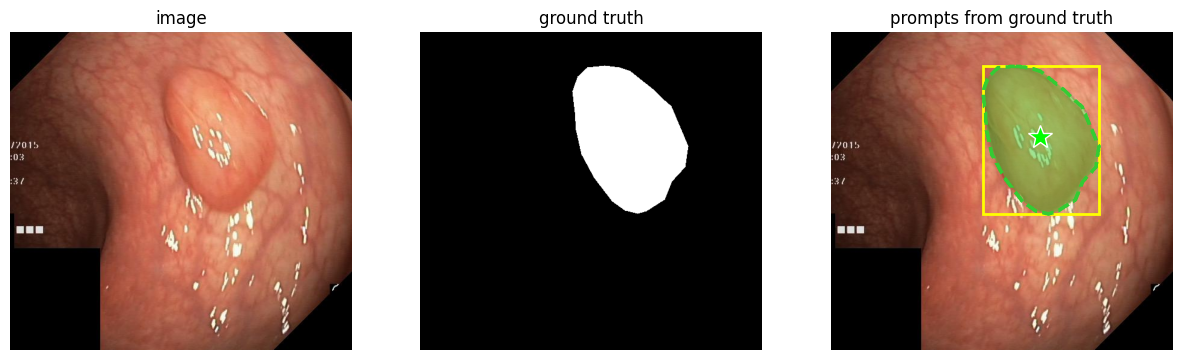

In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Circle
GT_C, SAM_C = (0.2, 0.8, 0.2), (1.0, 0.0, 0.8)     # 정답은 녹색, SAM 마스크는 자홍색

def show_gt(gt, ax, fill=False):
    if fill: show_mask(gt, ax, color=GT_C, alpha=0.45)
    ax.contour(gt, colors=[GT_C], linewidths=2.5, linestyles='--')

def show_pred(m, ax):
    show_mask(m, ax, color=SAM_C, alpha=0.45)
    if m.any():
        ax.contour(m, colors=[SAM_C], linewidths=2)
        if m.mean() < 0.01:                              # 아주 작은 마스크는 빨간 원으로 표시
            ys, xs = np.where(m)
            ax.add_patch(Circle((xs.mean(), ys.mean()), 0.07 * max(m.shape), fill=False, color='red', lw=2.5))

def polyp_legend(ax, sam=True, neg=False):
    items = [Line2D([], [], color=GT_C, lw=2.5, ls='--', label='ground truth')]
    if sam: items.append(Patch(color=SAM_C, alpha=0.6, label='SAM mask'))
    items.append(Line2D([], [], marker='*', color='lime', ls='', markersize=13, markeredgecolor='white', label='object point'))
    if neg: items.append(Line2D([], [], marker='*', color='red', ls='', markersize=13, markeredgecolor='white', label='background point'))
    ax.legend(handles=items, loc='lower right', fontsize=10, framealpha=0.9)

ratios = np.array([np.mean(np.array(Image.open(mask_paths[i]).convert('L')) > 127) for i in test_idx])
sample = test_idx[np.argmin(np.abs(ratios - np.median(ratios)))]    # 용종 크기가 중앙값에 가장 가까운 사진
image = Image.open(image_paths[sample]).convert('RGB')
gt = np.array(Image.open(mask_paths[sample]).convert('L')) > 127
point, box = prompts_from_mask(gt)
print(f'테스트 사진에서 용종이 차지하는 비율: 중앙값 {np.median(ratios) * 100:.1f}% (최소 {ratios.min() * 100:.1f}%, 최대 {ratios.max() * 100:.1f}%)')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(image); axes[0].set_title('image')
axes[1].imshow(gt, cmap='gray'); axes[1].set_title('ground truth')
axes[2].imshow(image); show_gt(gt, axes[2], fill=True)
show_points(point, [1], axes[2]); show_box(box, axes[2], color='yellow'); axes[2].set_title('prompts from ground truth')
for ax in axes: ax.axis('off')
plt.show()

점 프롬프트에서 Dice가 가장 낮았던 사진 3장을 봅니다. 위 줄은 정답(녹색), 아래 줄은 SAM이 고른 마스크(자홍색, 빨간 원 안)와 정답의 경계(녹색 점선)입니다. 별은 프롬프트로 준 점입니다.

정답 영역 32.2% / 고른 마스크 0.03% (점수 0.936) / 세 후보의 크기: ['21.96%', '0.04%', '0.03%']
정답 영역 12.9% / 고른 마스크 0.02% (점수 0.858) / 세 후보의 크기: ['10.69%', '0.12%', '0.02%']
정답 영역 57.9% / 고른 마스크 0.08% (점수 0.844) / 세 후보의 크기: ['82.14%', '0.08%', '0.04%']


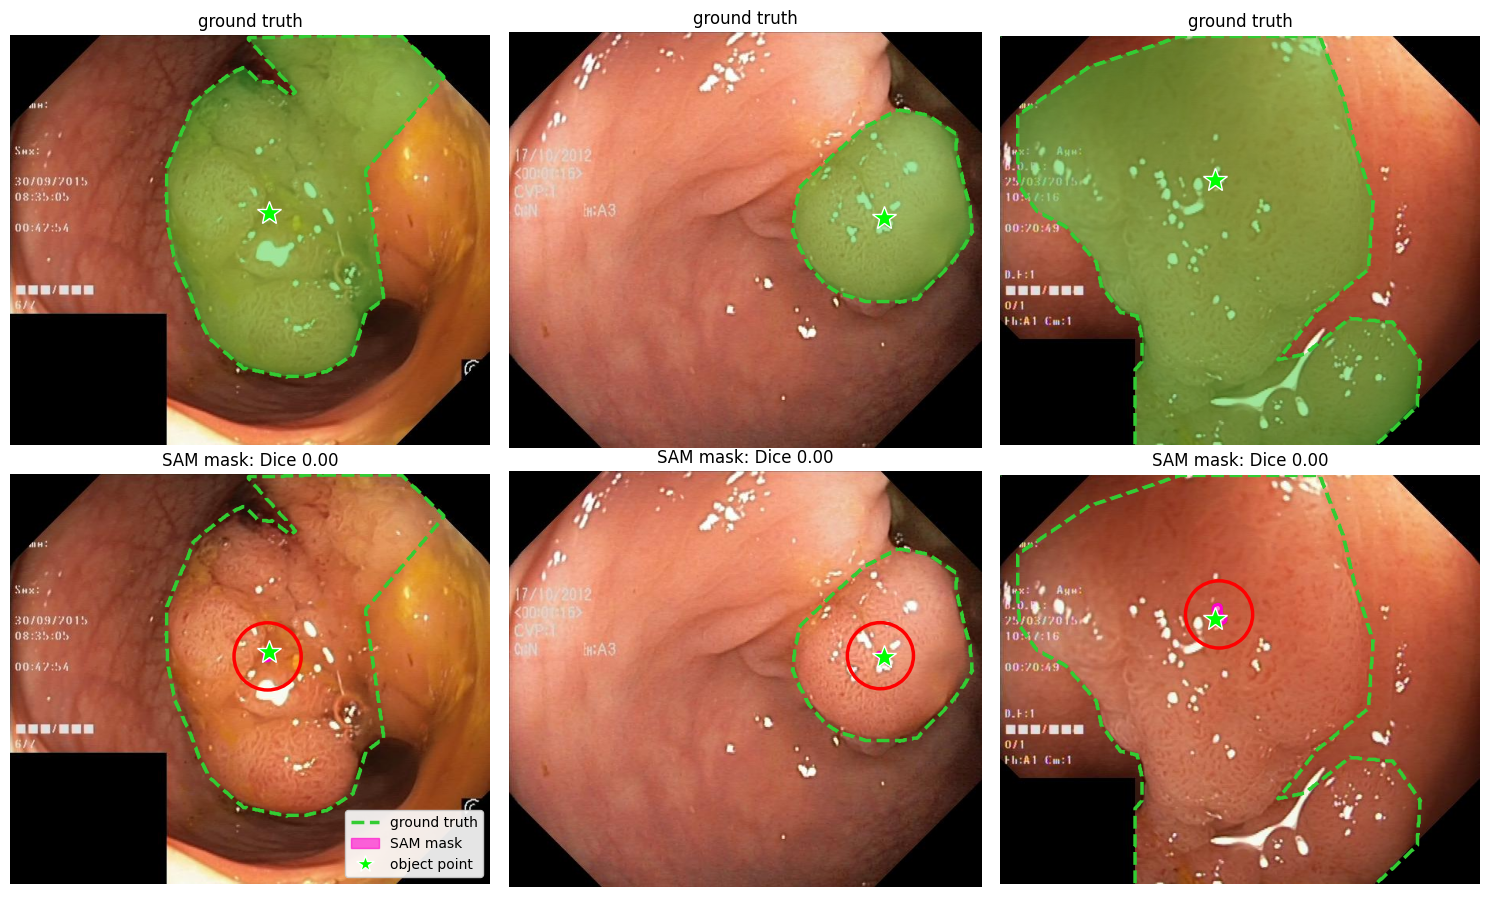

In [15]:
worst = test_idx[np.argsort(res_sam['point'])[:3]]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for k, i in enumerate(worst):
    image = Image.open(image_paths[i]).convert('RGB')
    gt = np.array(Image.open(mask_paths[i]).convert('L')) > 127
    point, box = prompts_from_mask(gt)
    masks, scores = run_sam(sam, proc, image, point=point)
    m = masks[scores.argmax()]
    ax = axes[0, k]; ax.imshow(image); show_gt(gt, ax, fill=True); show_points(point, [1], ax)
    ax.axis('off'); ax.set_title('ground truth')
    ax = axes[1, k]; ax.imshow(image); show_gt(gt, ax); show_pred(m, ax)
    show_points(point, [1], ax); ax.axis('off'); ax.set_title(f'SAM mask: Dice {dice(gt, m):.2f}')
    print(f'정답 영역 {gt.mean() * 100:.1f}% / 고른 마스크 {m.mean() * 100:.2f}% (점수 {scores.max():.3f})',
          '/ 세 후보의 크기:', [f'{x.mean() * 100:.2f}%' for x in masks])
polyp_legend(axes[1, 0])
plt.tight_layout(); plt.show()

### 클릭을 더하면: 사람이 고쳐 가는 과정 흉내 내기
SAM을 실제로 쓸 때는 결과를 보고 점을 더 찍어 고칩니다. 이 과정을 흉내 냅니다.
1. 첫 클릭은 앞에서처럼 용종 한가운데에 찍습니다.
2. 다음 클릭부터는 지금 마스크가 **가장 크게 틀린 곳**의 한가운데에 찍습니다. 용종인데 놓친 곳이면 물체 점(라벨 1), 용종이 아닌데 칠한 곳이면 배경 점(라벨 0)입니다.
3. 점이 둘 이상이면 원하는 것이 분명하므로 마스크 하나만 받습니다. 이때 바로 앞 단계의 마스크도 함께 넣어(마스크 프롬프트) 지금까지의 결과를 이어서 고치게 합니다. SAM 논문이 학습할 때 쓴 방식과 같습니다.

이미지 임베딩은 사진마다 한 번만 구하고, 클릭할 때마다 디코더만 다시 돌립니다.

In [16]:
def next_click(gt, pred):
    """가장 크게 틀린 영역의 한가운데 점과 그 라벨(놓친 곳 1, 넘친 곳 0)"""
    fn, fp = gt & ~pred, pred & ~gt
    d_fn, d_fp = distance_transform_edt(fn), distance_transform_edt(fp)
    err, label = (d_fn, 1) if d_fn.max() >= d_fp.max() else (d_fp, 0)
    if err.max() == 0: return None, None      # 틀린 곳이 없으면 더 찍지 않는다
    y, x = np.unravel_index(err.argmax(), err.shape)
    return [int(x), int(y)], label

def click_segment(image, emb, points, labels, prev=None):
    # 점들에 앞 단계 마스크(저해상도 로짓)까지 함께 넣는다. 첫 클릭만 후보 3개 중 고른다
    inp = proc(images=image, input_points=[[points]], input_labels=[[labels]], return_tensors='pt').to(device)
    inp.pop('pixel_values')
    extra = {} if prev is None else {'input_masks': prev}
    with torch.no_grad():
        out = sam(image_embeddings=emb, multimask_output=prev is None, **inp, **extra)
    j = int(out.iou_scores[0, 0].argmax())
    masks = proc.post_process_masks(out.pred_masks.cpu(), inp['original_sizes'].cpu(),
                                    inp['reshaped_input_sizes'].cpu())[0][0].numpy()
    return masks[j], out.pred_masks[0, 0, j][None, None]

N_CLICKS = 5
click_dice = np.zeros((len(test_idx), N_CLICKS))
t = time.time()
for r, i in enumerate(test_idx):
    image = Image.open(image_paths[i]).convert('RGB')
    gt_img = Image.open(mask_paths[i]).convert('L')
    gt = np.array(gt_img) > 127
    gt256 = np.array(gt_img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 127
    with torch.no_grad():
        emb_p = sam.get_image_embeddings(proc(images=image, return_tensors='pt')['pixel_values'].to(device))
    points, labels, prev = prompts_from_mask(gt)[0], [1], None
    for k in range(N_CLICKS):
        pred, prev = click_segment(image, emb_p, points, labels, prev)
        click_dice[r, k] = dice(gt256, to256(pred))
        p, l = next_click(gt, pred)
        if p is None:
            click_dice[r, k + 1:] = click_dice[r, k]; break
        points, labels = points + [p], labels + [l]
print(f'({time.time() - t:.0f}s)')
for k in range(N_CLICKS):
    print(f'클릭 {k + 1}번: Dice 평균 {click_dice[:, k].mean():.3f}, 0.3 미만 {(click_dice[:, k] < 0.3).sum()}장')
print(f'(비교) 박스 하나: {res_sam["box"].mean():.3f} / 7장 U-Net: 0.662')

(88s)
클릭 1번: Dice 평균 0.573, 0.3 미만 33장
클릭 2번: Dice 평균 0.804, 0.3 미만 8장
클릭 3번: Dice 평균 0.906, 0.3 미만 0장
클릭 4번: Dice 평균 0.943, 0.3 미만 0장
클릭 5번: Dice 평균 0.948, 0.3 미만 0장
(비교) 박스 하나: 0.864 / 7장 U-Net: 0.662


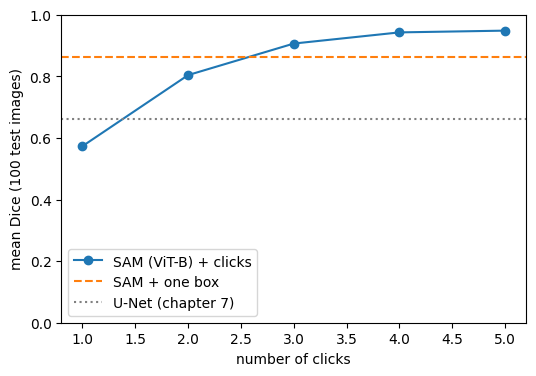

In [17]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, N_CLICKS + 1), click_dice.mean(0), 'o-', label='SAM (ViT-B) + clicks')
plt.axhline(res_sam['box'].mean(), color='tab:orange', ls='--', label='SAM + one box')
plt.axhline(0.662, color='gray', ls=':', label='U-Net (chapter 7)')
plt.xlabel('number of clicks'); plt.ylabel('mean Dice (100 test images)'); plt.ylim(0, 1); plt.legend()
plt.show()

점 프롬프트에서 가장 낮았던 사진 하나에 클릭을 네 번까지 더해 가며 마스크가 어떻게 바뀌는지 봅니다. 맨 왼쪽이 정답(녹색), 나머지는 녹색 점선이 정답의 경계, 자홍색이 SAM의 마스크입니다. 초록 별은 물체 점, 빨간 별은 배경 점입니다.

클릭 1번: Dice 0.002
클릭 2번: Dice 0.864
클릭 3번: Dice 0.780
클릭 4번: Dice 0.940


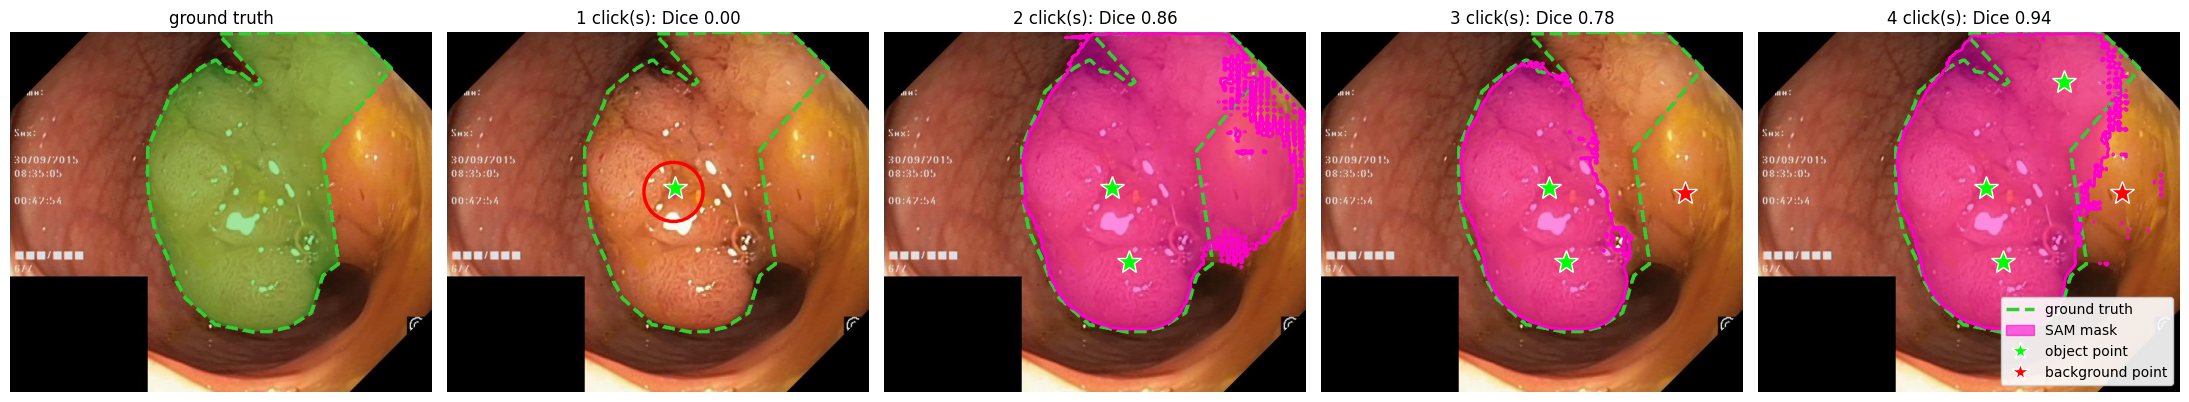

In [18]:
i = worst[0]
image = Image.open(image_paths[i]).convert('RGB')
gt = np.array(Image.open(mask_paths[i]).convert('L')) > 127
with torch.no_grad():
    emb_p = sam.get_image_embeddings(proc(images=image, return_tensors='pt')['pixel_values'].to(device))
points, labels, prev = prompts_from_mask(gt)[0], [1], None
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].imshow(image); show_gt(gt, axes[0], fill=True); axes[0].axis('off'); axes[0].set_title('ground truth')
for k, ax in enumerate(axes[1:]):
    pred, prev = click_segment(image, emb_p, points, labels, prev)
    ax.imshow(image); show_gt(gt, ax); show_pred(pred, ax)
    show_points(points, labels, ax); ax.axis('off'); ax.set_title(f'{k + 1} click(s): Dice {dice(gt, pred):.2f}')
    print(f'클릭 {k + 1}번: Dice {dice(gt, pred):.3f}')
    p, l = next_click(gt, pred)
    if p is None: break
    points, labels = points + [p], labels + [l]
polyp_legend(axes[-1], neg=True)
plt.tight_layout(); plt.show()

프롬프트가 없으면 어떨까요? 앞에서 본 사진(용종 크기가 중간쯤인 사진)을 자동 전체 분할에 넣고, 정답과 가장 잘 맞는 마스크를 찾아봅니다.

용종이 차지하는 비율: 11.0% / 마스크 수: 33
정답과 가장 잘 맞는 자동 마스크: Dice 0.954 (크기 10.1%)
Dice 0.5를 넘는 자동 마스크: 1개


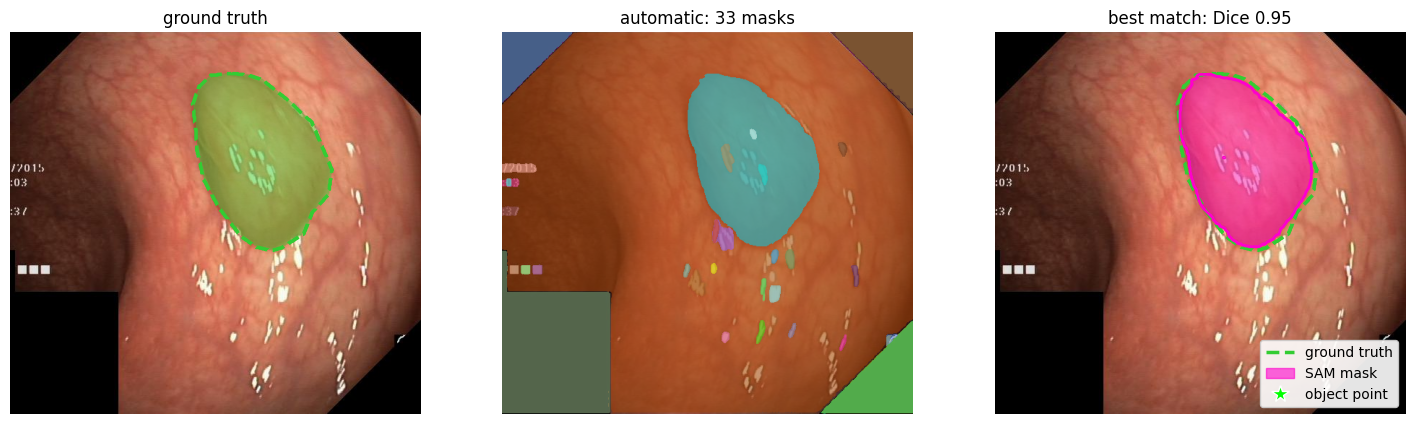

In [19]:
polyp = Image.open(image_paths[sample]).convert('RGB')
auto_p = generator(polyp, points_per_batch=64)
gt = np.array(Image.open(mask_paths[sample]).convert('L')) > 127
auto_masks = [torch.as_tensor(m).cpu().numpy().astype(bool) for m in auto_p['masks']]
d_auto = [dice(gt, m) for m in auto_masks]
best = auto_masks[int(np.argmax(d_auto))]
print(f'용종이 차지하는 비율: {gt.mean() * 100:.1f}% / 마스크 수: {len(auto_masks)}')
print(f'정답과 가장 잘 맞는 자동 마스크: Dice {max(d_auto):.3f} (크기 {best.mean() * 100:.1f}%)')
print(f'Dice 0.5를 넘는 자동 마스크: {sum(d > 0.5 for d in d_auto)}개')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(polyp); show_gt(gt, axes[0], fill=True); axes[0].set_title('ground truth')
axes[1].imshow(polyp)
rng = np.random.default_rng(0)
for m in sorted(auto_masks, key=lambda m: -m.sum()):
    show_mask(m, axes[1], color=rng.random(3), alpha=0.55)
axes[1].set_title(f'automatic: {len(auto_masks)} masks')
axes[2].imshow(polyp); show_gt(gt, axes[2]); show_pred(best, axes[2]); polyp_legend(axes[2])
axes[2].set_title(f'best match: Dice {max(d_auto):.2f}')
for ax in axes: ax.axis('off')
plt.show()

한 장만 보고 판단하지 않도록 테스트 100장 모두에 자동 전체 분할을 해서, 사진마다 정답과 가장 잘 맞는 마스크의 Dice를 잽니다. 평가는 앞에서처럼 256×256으로 줄여서 잽니다. GPU에서 10분쯤 걸립니다.

In [20]:
best_auto, n_masks = [], []
t = time.time()
for i in test_idx:
    image = Image.open(image_paths[i]).convert('RGB')
    gt_img = Image.open(mask_paths[i]).convert('L')
    gt256 = np.array(gt_img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 127
    ms = [torch.as_tensor(m).cpu().numpy().astype(bool) for m in generator(image, points_per_batch=64)['masks']]
    best_auto.append(max([dice(gt256, to256(m)) for m in ms], default=0.0))   # 정답을 보고 고른 가장 좋은 마스크
    n_masks.append(len(ms))
best_auto = np.array(best_auto)
print(f'자동 전체 분할 {len(test_idx)}장, 사진당 마스크 평균 {np.mean(n_masks):.0f}개 ({time.time() - t:.0f}s)')
print(f'정답과 가장 잘 맞는 자동 마스크의 Dice: 평균 {best_auto.mean():.3f}, 중앙값 {np.median(best_auto):.3f}')
print(f'0.8 이상 {(best_auto >= 0.8).sum()}장 / 0.5 미만 {(best_auto < 0.5).sum()}장')

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


자동 전체 분할 100장, 사진당 마스크 평균 37개 (563s)
정답과 가장 잘 맞는 자동 마스크의 Dice: 평균 0.534, 중앙값 0.489
0.8 이상 38장 / 0.5 미만 51장


## 5. 실습 ③: YOLO로 찾고 SAM으로 칠하기
SAM은 "무엇"을 모르고, YOLO는 "무엇"과 "어디"(박스)는 알지만 정확한 모양은 모릅니다.
7장의 YOLO(COCO 80개 범주로 사전학습한 가장 작은 YOLO11n)로 물체를 찾고, 그 박스를 SAM의 프롬프트로 넣어 봅니다.

In [21]:
yolo = YOLO('yolo11n.pt')
dog = Image.open('dog.jpg').convert('RGB')
det = yolo(dog, verbose=False)[0]
boxes = det.boxes.xyxy.cpu().numpy().round().astype(int).tolist()
names = [det.names[int(c)] for c in det.boxes.cls]
for n, s, b in zip(names, det.boxes.conf.cpu().numpy(), boxes):
    print(f'{n:8s} {s:.2f} {b}')

dog      0.94 [1, 222, 419, 530]
person   0.89 [509, 1, 799, 435]
bowl     0.81 [490, 138, 660, 262]


마스크: (3, 534, 800) / 점수: [      1.002       0.963       0.977]


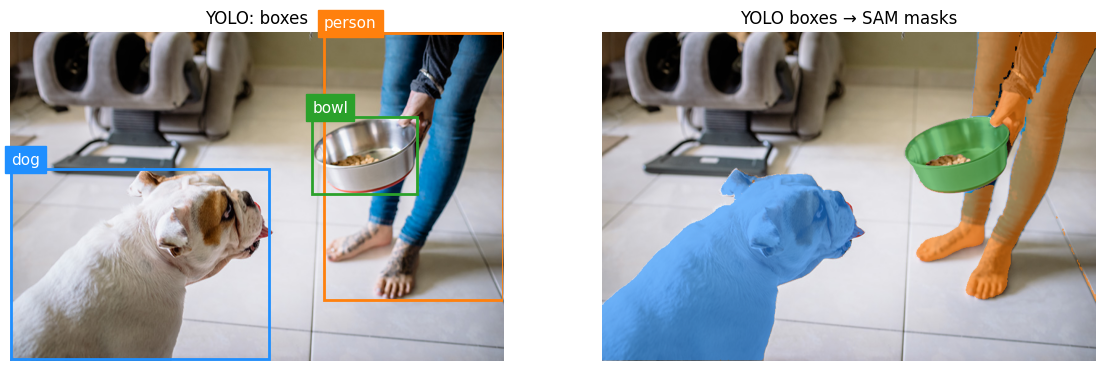

In [22]:
inp = proc(images=dog, input_boxes=[boxes], return_tensors='pt').to(device)    # 박스 여러 개를 한 번에
with torch.no_grad():
    out = sam(**inp, multimask_output=False)
masks = proc.post_process_masks(out.pred_masks.cpu(), inp['original_sizes'].cpu(),
                                inp['reshaped_input_sizes'].cpu())[0][:, 0].numpy()
print('마스크:', masks.shape, '/ 점수:', out.iou_scores[0, :, 0].cpu().numpy().round(3))

colors = [(0.12, 0.56, 1.0), (1.0, 0.5, 0.05), (0.17, 0.63, 0.17)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(dog); axes[0].set_title('YOLO: boxes'); axes[1].imshow(dog); axes[1].set_title('YOLO boxes → SAM masks')
for k, (n, b, m) in enumerate(zip(names, boxes, masks)):
    c = colors[k % 3]
    show_box(b, axes[0], color=c); axes[0].text(b[0], b[1] - 8, n, color='white', backgroundcolor=c, fontsize=11)
    show_mask(m, axes[1], color=c, alpha=0.6)
for ax in axes: ax.axis('off')
plt.show()

## 실습
1. **점의 위치**: 점을 앞바퀴 `[1500, 680]`에 찍으면 세 마스크는 각각 무엇을 칠할까요?
2. **점과 박스를 함께**: 용종 테스트 사진 100장에 점과 박스를 함께 프롬프트로 주면 Dice가 박스만 줄 때보다 좋아질까요?
3. **YOLO가 모르는 물체**: 3절에서 쓴, 종이봉투가 실린 자동차 트렁크 사진(`groceries.jpg`)을 YOLO로 검출해 보세요. 종이봉투를 찾을까요?

아래에 예시 답안이 있습니다.

마스크 0: 점수 0.726, 사진에서 차지하는 비율 29.8%
마스크 1: 점수 0.984, 사진에서 차지하는 비율 1.8%
마스크 2: 점수 0.984, 사진에서 차지하는 비율 0.6%


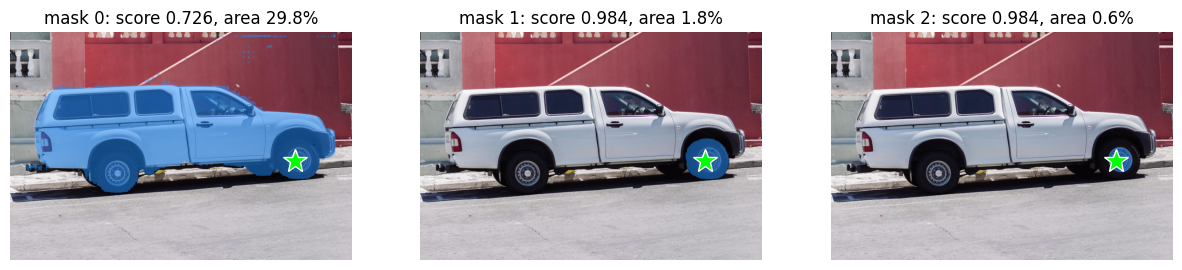

In [23]:
# 1. 점의 위치
pt3, lb3 = [[1500, 680]], [1]
masks, scores = segment(truck, emb, points=pt3, labels=lb3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, ax in enumerate(axes):
    ax.imshow(truck); show_mask(masks[i], ax); show_points(pt3, lb3, ax); ax.axis('off')
    ax.set_title(f'mask {i}: score {scores[i]:.3f}, area {masks[i].mean() * 100:.1f}%')
    print(f'마스크 {i}: 점수 {scores[i]:.3f}, 사진에서 차지하는 비율 {masks[i].mean() * 100:.1f}%')
plt.show()

In [24]:
# 2. 점과 박스를 함께
res_both = []
for i in test_idx:
    image = Image.open(image_paths[i]).convert('RGB')
    gt_img = Image.open(mask_paths[i]).convert('L')
    gt = np.array(gt_img) > 127
    gt256 = np.array(gt_img.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 127
    point, box = prompts_from_mask(gt)
    inp = proc(images=image, input_points=[[point]], input_labels=[[[1]]], input_boxes=[[box]],
               return_tensors='pt').to(device)
    with torch.no_grad():
        out = sam(**inp, multimask_output=False)
    m = proc.post_process_masks(out.pred_masks.cpu(), inp['original_sizes'].cpu(),
                                inp['reshaped_input_sizes'].cpu())[0][0, 0].numpy()
    res_both.append(dice(gt256, np.array(Image.fromarray(m).resize((IMG_SIZE, IMG_SIZE), Image.NEAREST))))
print(f'SAM (ViT-B) 점 + 박스: Dice {np.mean(res_both):.3f} (박스만 {res_sam["box"].mean():.3f})')

SAM (ViT-B) 점 + 박스: Dice 0.898 (박스만 0.864)


In [25]:
# 3. YOLO가 모르는 물체
det = yolo(groceries, verbose=False)[0]
print([(det.names[int(c)], round(float(s), 2)) for c, s in zip(det.boxes.cls, det.boxes.conf)])

[('car', 0.89), ('handbag', 0.26)]
